# Lab Assignment 1 - Convolutional Neural Networks

This notebook contains the **Part B** assignment tasks.
Use the lab session notebook for Part A demos and architecture notes (A9) if needed. Implement your solutions in the code cells below.

# Part B Assignment

Use this section to develop the main tasks and, optionally, the two challenges. Each task has a broad description followed by one consolidated answer code cell. You may design different interfaces, experiments and plots. Justify your choices and follow the accompanying assignment description for submission requirements.

## Task 1. Study and Prepare the Data

In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from pathlib import Path
# cpu as a fallback
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: mps


In [122]:
from IPython.display import display
from torchvision.datasets.utils import download_and_extract_archive
DATA_ROOT = Path("data")
try:
  database = datasets.CIFAR10(DATA_ROOT, train=True, download=False)
except:
  # faster than download with datasets
  download_and_extract_archive(
      "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz",
      download_root=str(DATA_ROOT),
      filename="cifar-10-python.tar.gz",
      md5="c58f30108f718f92721af3b95e74349a",
  )
  database = datasets.CIFAR10(DATA_ROOT, train=True, download=False)

labels = np.asarray(database.targets)
class_names = database.classes

print("Images:", database.data.shape, database.data.dtype)
print("Pixel range:", database.data.min(), database.data.max())
display(
    pd.DataFrame(
        {
            "class": class_names,
            "count": np.bincount(labels, minlength=10),
        }
    )
)

Images: (50000, 32, 32, 3) uint8
Pixel range: 0 255


,class,count
0,airplane,5000
1,automobile,5000
2,bird,5000
3,cat,5000
4,deer,5000
5,dog,5000
6,frog,5000
7,horse,5000
8,ship,5000
9,truck,5000


**Q: What does an example represent, and how are the classes distributed?**

An example is a 32x32 RGB image with a single class label from the ten CIFAR-10 categories. The official training set has 50,000 images with pixel values in [0, 255], and the classes are balanced (5,000 images per class).


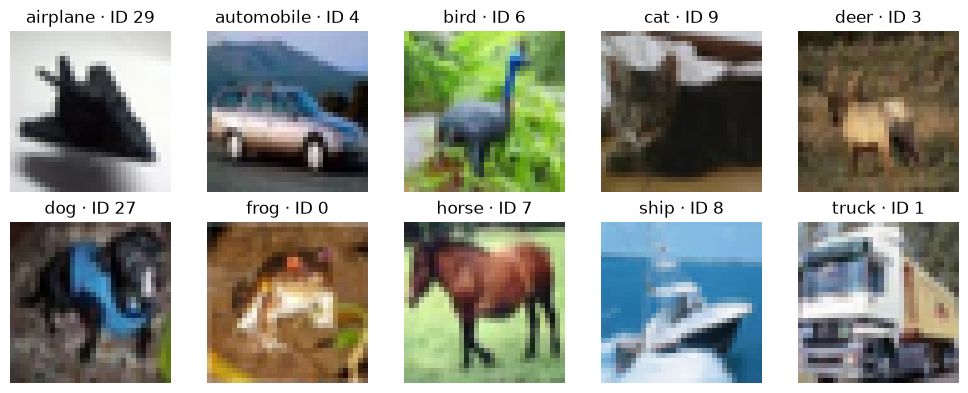

In [123]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for target, ax in enumerate(axes.flat):
    image_id = int(np.flatnonzero(labels == target)[0])
    ax.imshow(database.data[image_id])
    ax.set_title(f"{class_names[target]} · ID {image_id}")
    ax.axis("off")
fig.tight_layout()
plt.show()

In [124]:

from sklearn.model_selection import train_test_split
SEED = 2223

train_ids, val_ids = train_test_split(
    np.arange(len(database)),
    test_size=0.1,
    stratify=labels,
    random_state=SEED,
)
train_ids, val_ids = np.sort(train_ids), np.sort(val_ids)
assert set(train_ids).isdisjoint(val_ids)

print("Training / validation:", len(train_ids), len(val_ids))


Training / validation: 45000 5000


In [125]:
test_database = datasets.CIFAR10(DATA_ROOT, train=False, download=False)
test_ids = np.arange(len(test_database))
print("Test:", len(test_ids))
assert set(train_ids).isdisjoint(val_ids)

Test: 10000


In [126]:
from tqdm import tqdm

channel_sum = np.zeros(3)
channel_square_sum = np.zeros(3)
pixel_count = 0

# we process images in a batch of 256
for start in tqdm(range(0, len(train_ids), 256)):
    pixels = database.data[train_ids[start : start + 256]].astype(np.float64) / 255
    channel_sum += pixels.sum(axis=(0, 1, 2)) # sum across samples in a batch, image heights, image widths
    channel_square_sum += np.square(pixels).sum(axis=(0, 1, 2))
    pixel_count += np.prod(pixels.shape[:3])

mean = channel_sum / pixel_count
std = np.sqrt(np.maximum(channel_square_sum / pixel_count - mean**2, 1e-12))
stats = {"mean": mean.tolist(), "std": std.tolist()}
display(pd.DataFrame(stats, index=["red", "green", "blue"]))

100%|██████████| 176/176 [00:00<00:00, 1213.85it/s]


,mean,std
red,0.491318,0.247001
green,0.482180,0.243401
blue,0.446389,0.261544


In [127]:
class RawImages(Dataset):
    def __init__(self, dataset, ids):
        self.dataset = dataset
        self.ids = list(map(int, ids))

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):  # ty: ignore[lost-keyword-for-regular-parameter]
        image_id = self.ids[idx]
        image, target = self.dataset[image_id]
        return TF.to_tensor(image), int(target), image_id

In [128]:
def prepare_inputs(raw, stats):
    mean = raw.new_tensor(stats["mean"])[None, :, None, None]
    std = raw.new_tensor(stats["std"])[None, :, None, None]
    return (raw - mean) / std

**Q: Which preprocessing steps are needed for the two architectures?**

Both AlexNet and ResNet use the CIFAR-10 adaptations from Part A9, so they take native 3x32x32 inputs. We apply the same preprocessing to both: convert uint8 images to float tensors in [0, 1], then normalize each channel with the mean and standard deviation computed on the training split only.


**Q: How is the dataset preprocessed and splitted?**

We split the official training set into 45,000 training and 5,000 validation images (stratified 90/10, seed 2223). The official 10,000-image test set is held out for final evaluation. Images are converted to [0, 1] tensors and normalized with training-set mean/std.

In [140]:
import random
from dataclasses import asdict, dataclass, replace


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


@dataclass
class Run:
    name: str
    model: str = "AlexNet"
    group: str = "baseline"
    seed: int = 2223
    epochs: int = 20
    batch_size: int = 64
    lr: float = 0.01
    momentum: float = 0.9
    l2: float = 0.0
    dropout: float = 0.5
    width_mult: float = 1.0
    augmentation: bool = False
    smoke: bool = False

    def get_smoke(self, epochs: int = 1) -> "Run":
        return replace(self, smoke=True, epochs=epochs)


@dataclass
class Loaders:
    train: DataLoader
    train_eval: DataLoader
    val: DataLoader
    test: DataLoader | None = None


def make_loaders(run: Run, train_subset, val_subset, *, include_test=False) -> Loaders:
    generator = torch.Generator()
    generator.manual_seed(run.seed)
    loaders = Loaders(
        train=DataLoader(
            RawImages(database, train_subset),
            batch_size=run.batch_size,
            shuffle=True,
            num_workers=0,
            pin_memory=device.type == "cuda",
            generator=generator,
        ),
        train_eval=DataLoader(
            RawImages(database, train_subset),
            batch_size=run.batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=device.type == "cuda",
        ),
        val=DataLoader(
            RawImages(database, val_subset),
            batch_size=run.batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=device.type == "cuda",
        ),
    )
    if include_test:
        loaders.test = DataLoader(
            RawImages(test_database, test_ids),
            batch_size=run.batch_size,
            shuffle=False,
            num_workers=0,
            pin_memory=device.type == "cuda",
        )
    return loaders


inspect_run = Run(name="inspect", seed=SEED, batch_size=128, epochs=1)
set_seed(inspect_run.seed)
loaders = make_loaders(inspect_run, train_ids, val_ids, include_test=True)
print(
    f"{inspect_run.name}: "
    f"{len(loaders.train)} train / {len(loaders.val)} val / {len(loaders.test)} test batches"
)


inspect: 352 train / 40 val / 79 test batches


**Q: How to control the randomness in the experiment?**

We fix the train/validation split with `SEED = 2223`, seed Python/NumPy/PyTorch through `set_seed`, and rebuild each DataLoader shuffle generator from `Run.seed`. That keeps the partition and batch order stable across runs.


## Task 2. Implement and Compare the Models
Implement and train AlexNet and ResNet using PyTorch layers, starting from the architectures and CIFAR-10 adaptations discussed in A9. Explain any differences from the original designs, observe feature shapes and compare the models under a justified compute budget. Do not use pretrained weights or readily-available model constructors.

Choose your optimizer, training schedule, checkpoint rule and evaluation metrics. Justify your choices. Report numerical performance, parameter counts, training cost, number of trained samples and relevant limitations. You are free to define different model construction, training and evaluation rather than following part A.

In [130]:
# AlexNet
class AlexNet(nn.Module):
    def __init__(self, dropout: float = 0.5, width_mult: float = 1.0):
        super().__init__()

        def width(channels: int) -> int:
            return max(8, int(round(channels * width_mult)))

        c1, c2, c3, c4, c5 = map(width, (64, 192, 384, 256, 256))
        fc1, fc2 = map(width, (1024, 512))
        flat = c5 * 4 * 4

        self.network = nn.Sequential(
            nn.Conv2d(3, c1, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(c1, c2, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(c2, c3, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(c3, c4, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(c4, c5, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(flat, fc1),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(fc1, fc2),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(fc2, 10),
        )

    def forward(self, x):
        return self.network(x)


AlexNet()(torch.randn(2, 3, 32, 32)).shape


torch.Size([2, 10])

In [131]:
# BasicBlock

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                stride=stride,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=out_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                stride=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
        )

        self.shortcut = self.build_shortcut(in_channels, out_channels, stride)
        self.relu = nn.ReLU()

    def build_shortcut(self, in_channels, out_channels, stride):
        if stride == 1 and in_channels == out_channels:
            return nn.Identity()
        else:
            return nn.Sequential(
                nn.Conv2d(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        return self.relu(self.shortcut(x) + self.network(x))


print(BasicBlock(64, 64, 1)(torch.randn(2, 64, 32, 32)).shape)
print(BasicBlock(64, 128, 2)(torch.randn(2, 64, 32, 32)).shape)

torch.Size([2, 64, 32, 32])
torch.Size([2, 128, 16, 16])


In [132]:
# ResNet

class ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # Stage 1
            BasicBlock(64, 64, 1),
            BasicBlock(64, 64, 1),

            # Stage 2
            BasicBlock(64, 128, 2),
            BasicBlock(128, 128, 1),

            # Stage 3
            BasicBlock(128, 256, 2),
            BasicBlock(256, 256, 1),

            # Stage 4
            BasicBlock(256, 512, 2),
            BasicBlock(512, 512, 1),
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Flatten(),
            nn.Linear(
                in_features=512,
                out_features=10
            )
        )

    def forward(self, x):
        return self.network(x)

ResNet()(torch.randn(2, 3, 32, 32)).shape

torch.Size([2, 10])

In [133]:
import json
import time
import uuid
from datetime import datetime, timezone


def build_model(run: Run) -> nn.Module:
    if run.model == "AlexNet":
        return AlexNet(dropout=run.dropout, width_mult=run.width_mult)
    if run.model == "ResNet18":
        return ResNet()
    raise ValueError(f"Unknown model: {run.model}")


for run in (
    Run(name="check_alexnet", model="AlexNet"),
    Run(name="check_resnet", model="ResNet18"),
):
    model = build_model(run)
    print(run.model)
    print(model)
    print("parameters:", sum(p.numel() for p in model.parameters()))
    with torch.no_grad():
        out = model(torch.zeros(2, 3, 32, 32))
    assert out.shape == (2, 10)
    print("output shape:", tuple(out.shape), "\n")
    del model


AlexNet
AlexNet(
  (network): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Flatten(start_dim=1, end_dim=-1)
    (14): Linear(in_features=4096, out_features=1024, bias=True)
    (15): ReLU()
    (16): Dropout(p=0.5, inplace=False)
    (17): Linear(in_features=1024, out_features=512, bias=True)
    (18): ReL

**Q: Describe and justify the layers, feature-map dimensions, and parameter counts.**

We implement the CIFAR-10 adaptations from Part A9 with plain PyTorch layers (no pretrained weights and no torchvision model constructors).

AlexNet has five 3x3 convolutions with channels 64->192->384->256->256, stride 1 and padding 1, interleaved with three 2x2 max-pools, then a classifier 4096->1024->512->10 with dropout 0.5. After the pools the feature map is 256x4x4, which flattens to 4096 units. This network has about 6.98M parameters. Compared with the original ImageNet AlexNet we keep the smaller 3x3 stride-1 stem suited to 32x32 inputs, drop local response normalization, and use a thinner head for ten classes.

ResNet-18 uses a 3x3 stride-1 stem without the original 7x7 convolution or stem max-pool, then four stages of two basic blocks with widths 64->128->256->512 (stride 2 at the start of stages 2-4), global average pooling and a 512->10 linear layer. It has about 11.17M parameters. Convolutions followed by BatchNorm are created with `bias=False`, since BatchNorm already provides a learned shift.


**Q: Describe and justify the input preparation and classification head.**

Both architectures consume the same Task 1 inputs: images are converted to float tensors in [0, 1] and normalized with the mean and standard deviation estimated on the training split only. We keep resolution at 32x32, so no ImageNet-style upsampling is required.

AlexNet's classification head is the fully connected stack 4096->1024->512->10 with dropout 0.5 between the hidden layers. ResNet replaces that wide MLP with global average pooling over the final 512x4x4 map and a single linear layer to 10 logits. In both cases the network returns raw logits and `cross_entropy` applies the log-softmax internally.


**Q: Describe and justify the convolution operations, and the roles they play in the visual task.**

The 3x3 convolutions combine nearby pixels (and later nearby feature responses) into new channel activations, which is how the networks build cues for CIFAR object categories. With padding 1, a stride-1 convolution keeps height and width unchanged, so capacity goes into channels rather than shrinking the map too early. Downsampling is done explicitly: AlexNet uses 2x2 max-pooling, while ResNet uses stride-2 convolutions at the beginning of later stages. That reduction increases the receptive field, so deeper layers integrate information over larger regions of the 32x32 image.


**Q: Describe and justify the optimization and checkpoint-selection procedure.**

We train both models under one shared budget so the comparison is controlled: SGD with learning rate 0.01 and momentum 0.9, cosine decay over 20 epochs, batch size 64, seed 2223, and the same 45,000 / 5,000 train/validation split from Task 1. This baseline uses no data augmentation and no weight decay; AlexNet still uses the dropout from the A9 design. Equal epochs give both models the same number of training examples (900,000 visits including repeats), not equal wall-clock time.

After every epoch we measure validation accuracy and keep the checkpoint with the highest value, breaking ties with lower validation cross-entropy. The official test set is never used to pick a checkpoint.


**Q: Describe and justify the role of residual connections in ResNet.**

Each basic block computes a residual branch `F(x)` and adds it to a shortcut of `x`, then applies ReLU. When channel count and spatial size match, the shortcut is the identity; when the block downsamples or widens, the shortcut is a 1x1 convolution (with BatchNorm) that matches shapes. The skip path lets the block learn a residual correction instead of a full mapping and keeps a direct route for gradients through the stack, which is the main reason this deeper ResNet remains trainable compared with a plain conv stack of similar depth. This experiment still compares full architectures (width, BatchNorm, dropout), so it does not isolate skip connections by themselves.


In [134]:
SMOKE = False  # True = 1 epoch on a tiny ID slice (pipeline check only).

alexnet_run = Run(
    name="AlexNet",
    model="AlexNet",
    seed=SEED,
    epochs=20,
    batch_size=64,
    lr=0.01,
    momentum=0.9,
    l2=0.0,
    augmentation=False,
)
resnet_run = Run(
    name="ResNet18",
    model="ResNet18",
    seed=SEED,
    epochs=20,
    batch_size=64,
    lr=0.01,
    momentum=0.9,
    l2=0.0,
    augmentation=False,
)
if SMOKE:
    alexnet_run = alexnet_run.get_smoke()
    resnet_run = resnet_run.get_smoke()
    train_ids = train_ids[:512]
    val_ids = val_ids[:256]

In [135]:
# New folder each time so previous checkpoints are not overwritten.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
task2_output_dir = Path("outputs") / "task2" / f"{'smoke' if alexnet_run.smoke else 'full'}_{run_id}"
task2_output_dir.mkdir(parents=True, exist_ok=False)

(task2_output_dir / "config.json").write_text(
    json.dumps(
        {"runs": [asdict(alexnet_run), asdict(resnet_run)], "normalization": stats},
        indent=2,
    ),
    encoding="utf-8",
)
np.savez(task2_output_dir / "split_ids.npz", train_ids=train_ids, val_ids=val_ids)
print("Output directory:", task2_output_dir.resolve())


Output directory: /Users/lorenzo/git/kth/ID2223-Scalable-Machine-Learning-and-Deep-Learning/assignments/ass1/outputs/task2/full_20261119T172416Z_394a2c34


In [136]:
@dataclass
class Metrics:
    loss: float
    accuracy: float
    samples: int


@dataclass
class EpochResult:
    epoch: int
    train_loss: float
    train_accuracy: float
    val_loss: float
    val_accuracy: float


@dataclass
class RunSummary:
    name: str
    group: str
    model: str
    smoke: bool
    epochs: int
    dropout: float
    width_mult: float
    l2: float
    parameters: int
    best_epoch: int
    best_val_accuracy: float
    best_val_loss: float
    trained_samples: int
    wall_seconds: float
    checkpoint: str


In [137]:
def train_batch(model, batch, optimizer):
    raw, targets, _ = batch
    raw, targets = raw.to(device), targets.to(device)
    optimizer.zero_grad(set_to_none=True)
    logits = model(prepare_inputs(raw, stats))
    loss = nn.functional.cross_entropy(logits, targets)
    loss.backward()
    optimizer.step()
    count = len(targets)
    correct = (logits.argmax(1) == targets).sum().item()
    return loss.item() * count, correct, count


def train_epoch(model, loader, optimizer, run, epoch) -> Metrics:
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for batch in tqdm(loader, desc=f"[{epoch}/{run.epochs}] {run.name}"):
        batch_loss, batch_correct, batch_count = train_batch(model, batch, optimizer)
        loss_sum += batch_loss
        correct += batch_correct
        count += batch_count
    return Metrics(loss=loss_sum / count, accuracy=correct / count, samples=count)


@torch.inference_mode()
def evaluate(model, loader, normalization_stats=None) -> Metrics:
    if normalization_stats is None:
        normalization_stats = stats
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for raw, targets, _ in loader:
        raw, targets = raw.to(device), targets.to(device)
        logits = model(prepare_inputs(raw, normalization_stats))
        loss_sum += nn.functional.cross_entropy(logits, targets, reduction="sum").item()
        correct += (logits.argmax(1) == targets).sum().item()
        count += targets.size(0)
    return Metrics(loss=loss_sum / count, accuracy=correct / count, samples=count)


def train_model(
    run: Run,
    *,
    output_dir: Path,
    train_ids,
    val_ids,
) -> tuple[list[EpochResult], RunSummary]:
    set_seed(run.seed)
    loaders = make_loaders(run, train_ids, val_ids)
    model = build_model(run).to(device)
    optimizer = torch.optim.SGD(
        model.parameters(), lr=run.lr, momentum=run.momentum, weight_decay=run.l2
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=run.epochs)
    checkpoint_path = output_dir / f"{run.name}_best.pt"

    history: list[EpochResult] = []
    best_key, best_epoch = None, None
    start = time.perf_counter()
    for epoch in range(1, run.epochs + 1):
        training = train_epoch(model, loaders.train, optimizer, run, epoch)
        validation = evaluate(model, loaders.val)
        history.append(
            EpochResult(
                epoch=epoch,
                train_loss=training.loss,
                train_accuracy=training.accuracy,
                val_loss=validation.loss,
                val_accuracy=validation.accuracy,
            )
        )

        key = (validation.accuracy, -validation.loss)
        if best_key is None or key > best_key:
            best_key, best_epoch = key, epoch
            torch.save(
                {
                    "model_name": run.model,
                    "epoch": epoch,
                    "config": asdict(run),
                    "stats": stats,
                    "class_names": class_names,
                    "val_loss": validation.loss,
                    "val_accuracy": validation.accuracy,
                    "state_dict": {
                        k: v.detach().cpu().clone() for k, v in model.state_dict().items()
                    },
                },
                checkpoint_path,
            )

        scheduler.step()
        pd.DataFrame(map(asdict, history)).to_csv(
            output_dir / f"{run.name}_history.csv", index=False
        )

    assert best_key is not None and best_epoch is not None
    summary = RunSummary(
        name=run.name,
        group=run.group,
        model=run.model,
        smoke=run.smoke,
        epochs=run.epochs,
        dropout=run.dropout,
        width_mult=run.width_mult,
        l2=run.l2,
        parameters=sum(p.numel() for p in model.parameters()),
        best_epoch=best_epoch,
        best_val_accuracy=best_key[0],
        best_val_loss=-best_key[1],
        trained_samples=run.epochs * len(train_ids),
        wall_seconds=time.perf_counter() - start,
        checkpoint=str(checkpoint_path),
    )
    del model, optimizer, scheduler
    return history, summary


In [83]:
histories, summaries = {}, []
for run in (alexnet_run, resnet_run):
    histories[run.name], summary = train_model(
        run, output_dir=task2_output_dir, train_ids=train_ids, val_ids=val_ids
    )
    summaries.append(summary)
    comparison = pd.DataFrame(map(asdict, summaries))
    comparison.to_csv(task2_output_dir / "comparison.csv", index=False)
display(comparison)
if alexnet_run.smoke:
    print("SMOKE CHECK ONLY: set SMOKE=False and rerun from the configuration cell for report results.")


[20/20] ResNet18: 100%|██████████| 704/704 [00:35<00:00, 19.74it/s]


,model,smoke,epochs,parameters,best_epoch,best_val_accuracy,best_val_loss,trained_samples,wall_seconds,checkpoint
0,AlexNet,False,20,6976842,17,0.8384,0.880100,900000,296.991658,outputs/task2/full_20261118T151309Z_9b5cbcb2/A...
1,ResNet18,False,20,11173962,18,0.8574,0.677354,900000,776.154655,outputs/task2/full_20261118T151309Z_9b5cbcb2/R...


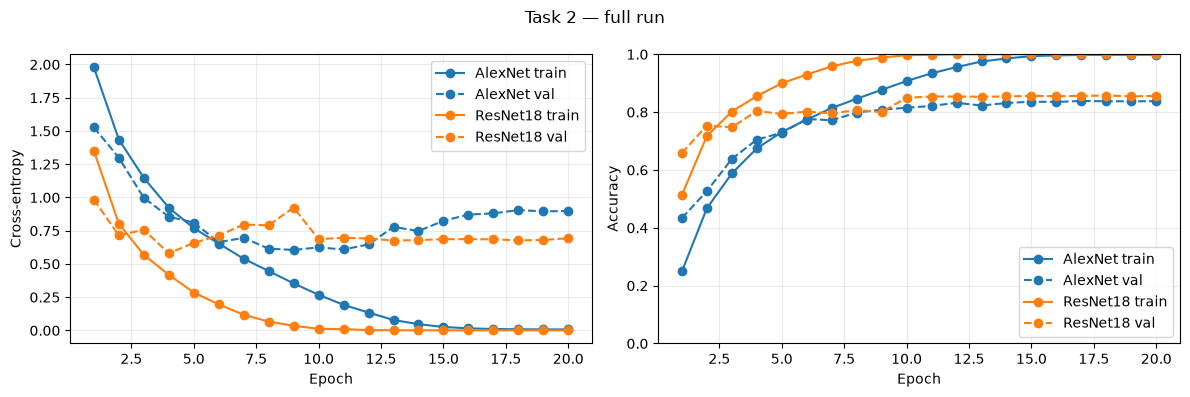

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    epochs = [row.epoch for row in history]
    line, = axes[0].plot(epochs, [row.train_loss for row in history], marker="o", label=f"{name} train")
    color = line.get_color()
    axes[0].plot(epochs, [row.val_loss for row in history], "--o", color=color, label=f"{name} val")
    axes[1].plot(epochs, [row.train_accuracy for row in history], "-o", color=color, label=f"{name} train")
    axes[1].plot(epochs, [row.val_accuracy for row in history], "--o", color=color, label=f"{name} val")
axes[0].set_ylabel("Cross-entropy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.25)
fig.suptitle(f"Task 2 — {'smoke' if alexnet_run.smoke else 'full'} run")
fig.tight_layout()
fig.savefig(task2_output_dir / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()


**Q: Compare the models under a clearly stated compute budget. Report performance, parameter counts, training cost, trained samples and limitations.**

We compare the two baselines on Apple MPS in run `full_20261118T151309Z_9b5cbcb2`, with the shared 20-epoch budget. Each model therefore sees 900,000 training examples across epochs. The table reports the selected validation checkpoint for each network.

| | AlexNet | ResNet-18 |
|---|---:|---:|
| Parameters | 6,976,842 | 11,173,962 |
| Best epoch | 17 | 18 |
| Validation accuracy | 83.84% | 85.74% |
| Validation loss at best | 0.880 | 0.677 |
| Training accuracy at best | 99.78% | 100% |
| Wall-clock time | 4.95 min | 12.94 min |

ResNet reaches a higher validation accuracy (+1.90 percentage points) with about 1.6x as many parameters, at roughly 2.6x the wall time on this machine. Both fits show overfitting: training accuracy is near-perfect while validation stays in the mid-80% range. The comparison uses one seed and one split, and the official test set is still held out for later final evaluation.


## Task 3. Investigate Capacity and Regularization
Investigate how model capacity (n_channels/width, depth, etc.) and regularization influence learning and generalization. Select a feasible set of comparisons and justify what you change and hold fixed. Include L2 regularization, a condition without dropout and two dropout probabilities of your choice. Use learning curves and deterministic training/validation evaluation to distinguish underfitting, overfitting and incomplete optimization.

You may choose either architecture, modify different stages, or use another controlled experimental design.

In [138]:
TASK3_SMOKE = False  # True = 1 epoch on a tiny ID slice (pipeline check only).

baseline = Run(
    name="alexnet_baseline",
    model="AlexNet",
    group="shared",
    seed=SEED,
    epochs=20,
    batch_size=64,
    lr=0.01,
    momentum=0.9,
    l2=0.0,
    dropout=0.5,
    width_mult=1.0,
    augmentation=False,
)

task3_runs: list[Run] = [
    baseline,
    replace(baseline, name="alexnet_w0.5", group="capacity", width_mult=0.5),
    replace(baseline, name="alexnet_w1.5", group="capacity", width_mult=1.5),
    replace(baseline, name="alexnet_l2_1e-4", group="l2", l2=1e-4),
    replace(baseline, name="alexnet_l2_1e-3", group="l2", l2=1e-3),
    replace(baseline, name="alexnet_dropout_0.0", group="dropout", dropout=0.0),
    replace(baseline, name="alexnet_dropout_0.25", group="dropout", dropout=0.25),
]

task3_group_members: dict[str, list[str]] = {
    "capacity": ["alexnet_w0.5", "alexnet_baseline", "alexnet_w1.5"],
    "l2": ["alexnet_baseline", "alexnet_l2_1e-4", "alexnet_l2_1e-3"],
    "dropout": ["alexnet_dropout_0.0", "alexnet_dropout_0.25", "alexnet_baseline"],
}

if TASK3_SMOKE:
    task3_runs = [run.get_smoke() for run in task3_runs]
    task3_train_ids = train_ids[:512]
    task3_val_ids = val_ids[:256]
else:
    task3_train_ids = train_ids
    task3_val_ids = val_ids

print("Task 3 runs:")
for run in task3_runs:
    print(asdict(run))


Task 3 runs:
{'name': 'alexnet_baseline', 'model': 'AlexNet', 'group': 'shared', 'seed': 2223, 'epochs': 20, 'batch_size': 64, 'lr': 0.01, 'momentum': 0.9, 'l2': 0.0, 'dropout': 0.5, 'width_mult': 1.0, 'augmentation': False, 'smoke': False}
{'name': 'alexnet_w0.5', 'model': 'AlexNet', 'group': 'capacity', 'seed': 2223, 'epochs': 20, 'batch_size': 64, 'lr': 0.01, 'momentum': 0.9, 'l2': 0.0, 'dropout': 0.5, 'width_mult': 0.5, 'augmentation': False, 'smoke': False}
{'name': 'alexnet_w1.5', 'model': 'AlexNet', 'group': 'capacity', 'seed': 2223, 'epochs': 20, 'batch_size': 64, 'lr': 0.01, 'momentum': 0.9, 'l2': 0.0, 'dropout': 0.5, 'width_mult': 1.5, 'augmentation': False, 'smoke': False}
{'name': 'alexnet_l2_1e-4', 'model': 'AlexNet', 'group': 'l2', 'seed': 2223, 'epochs': 20, 'batch_size': 64, 'lr': 0.01, 'momentum': 0.9, 'l2': 0.0001, 'dropout': 0.5, 'width_mult': 1.0, 'augmentation': False, 'smoke': False}
{'name': 'alexnet_l2_1e-3', 'model': 'AlexNet', 'group': 'l2', 'seed': 2223, 'epo

In [139]:
task3_run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
task3_output_dir = Path("outputs") / "task3" / f"{'smoke' if TASK3_SMOKE else 'full'}_{task3_run_id}"
task3_output_dir.mkdir(parents=True, exist_ok=False)

(task3_output_dir / "config.json").write_text(
    json.dumps(
        {
            "runs": [asdict(run) for run in task3_runs],
            "group_members": task3_group_members,
            "normalization": stats,
            "train_size": len(task3_train_ids),
            "validation_size": len(task3_val_ids),
        },
        indent=2,
    ),
    encoding="utf-8",
)
np.savez(task3_output_dir / "split_ids.npz", train_ids=task3_train_ids, val_ids=task3_val_ids)
print("Output directory:", task3_output_dir.resolve())


Output directory: /Users/lorenzo/git/kth/ID2223-Scalable-Machine-Learning-and-Deep-Learning/assignments/ass1/outputs/task3/full_20261119T172504Z_309c288e


In [ ]:
task3_histories: dict[str, list[EpochResult]] = {}
task3_summaries: list[RunSummary] = []
for run in task3_runs:
    task3_histories[run.name], summary = train_model(
        run,
        output_dir=task3_output_dir,
        train_ids=task3_train_ids,
        val_ids=task3_val_ids,
    )
    task3_summaries.append(summary)
    comparison_task3 = pd.DataFrame(map(asdict, task3_summaries))
    comparison_task3.to_csv(task3_output_dir / "comparison.csv", index=False)
display(comparison_task3)
if TASK3_SMOKE:
    print("SMOKE CHECK ONLY: set TASK3_SMOKE=False and rerun from the configuration cell for report results.")


In [ ]:
groups = ["capacity", "l2", "dropout"]
fig, axes = plt.subplots(len(groups), 2, figsize=(12, 3.8 * len(groups)), sharex=True)

for row, group in enumerate(groups):
    for name in task3_group_members[group]:
        history = task3_histories[name]
        epochs = [point.epoch for point in history]
        line, = axes[row, 0].plot(
            epochs, [point.train_loss for point in history], marker="o", label=f"{name} train"
        )
        color = line.get_color()
        axes[row, 0].plot(
            epochs, [point.val_loss for point in history], "--o", color=color, label=f"{name} val"
        )
        axes[row, 1].plot(
            epochs, [point.train_accuracy for point in history], "-o", color=color, label=f"{name} train"
        )
        axes[row, 1].plot(
            epochs, [point.val_accuracy for point in history], "--o", color=color, label=f"{name} val"
        )
    axes[row, 0].set_ylabel(f"{group}\ncross-entropy")
    axes[row, 1].set_ylabel(f"{group}\naccuracy")
    axes[row, 1].set_ylim(0, 1)
    for ax in axes[row]:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

axes[-1, 0].set_xlabel("Epoch")
axes[-1, 1].set_xlabel("Epoch")
fig.suptitle(f"Task 3 - {'smoke' if TASK3_SMOKE else 'full'} runs")
fig.tight_layout()
fig.savefig(task3_output_dir / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()


**Q: What did we change, what did we hold fixed, and what do the curves suggest?**

We keep AlexNet, the Task 1 split, seed, 20-epoch SGD+cosine budget, batch size 64 and no augmentation. One shared baseline (`width_mult=1.0`, `dropout=0.5`, `l2=0`) is reused across groups. Capacity changes only `width_mult` (0.5 / 1.0 / 1.5). L2 changes only weight decay (`0` / `1e-4` / `1e-3`). Dropout changes only the head dropout (`0` / `0.25` / `0.5`).

Conclusions from the curves and comparison table go here after the full Task 3 run.


## Task 4. Evaluate Robustness
Investigate whether training augmentation improves performance on clean and corrupted images. Choose suitable transformations and parameters, explain how they relate to image changes, and compare models on the same evaluation images. Separate random training views from reproducible evaluation corruptions. Discuss label ambiguity, changed error patterns and cost.

You may start with crop/flip or other corruptions. Develop the method on validation data, and freeze it for final testing.

In [87]:
# code

## Task 5. Analyse Predictions and Adversarial Examples
Combine quantitative evaluation with examples of successful and unsuccessful predictions. Decide which metrics, visualizations and examples best explain the models' behaviour. Generate an adversarial input against a trained model, describe the perturbation, and assess the observed effect. Distinguish deliberately optimized perturbations from random corruption. Define success for the adversarial attacks. Explain class-specific errors, learning curves and representative images alongside the numerical results.

In [88]:
# code

## Task 6. Benchmark and Discuss the Tradeoffs
Measure the costs that matter for your intended use and relate them to accuracy, robustness and the compute budget. Choose and describe an inference timing, device, precision and batch size. Discuss how training duration, randomness and hardware constrain the conclusions, and recommend a model or configuration using your measured evidence.

In [89]:
# code

## Challenge 1. Model Compression
Investigate whether a trained model can be represented by a smaller or faster model without an unacceptable loss in performance. Choose a method, define what efficiency and acceptable accuracy change mean for your use case, and compare the result with an appropriate reference under a consistent protocol. Report compression or fine-tuning cost as well as deployment cost. A smaller parameter count, sparse mask or smaller file does not automatically imply faster inference.

In [90]:
# code

## Challenge 2. Generalization Beyond the Development Conditions
Investigate whether your model generalizes to an unseen corruption family or a different, suitably labelled image domain. Choose a meaningful shift, explain its relationship to development data, and decide how to measure success. Discuss your findings.

In [91]:
# code

## References
- [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html)
- [AlexNet original paper](https://papers.nips.cc/paper/4824-imagenet-classification-with-deep-convolutional-neural-networks)
- [ResNet original paper](https://arxiv.org/abs/1512.03385)
- [PyTorch Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) and [LocalResponseNorm](https://docs.pytorch.org/docs/stable/generated/torch.nn.LocalResponseNorm.html)
- [FGSM background](https://docs.pytorch.org/tutorials/beginner/fgsm_tutorial.html)